In [ ]:
%pip install torch torchvision torchaudio
%pip install numpy pandas matplotlib seaborn scikit-learn



   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.3/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.3/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.3/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.5/124.1 MB 473.3 kB/s eta 0:04:22
   ---------------------------------------- 0.5/124.1 MB 473.3 kB/s eta 0:04:22
   ---------------------------------------- 0.5/124.1 MB 473.3 kB/s eta 0:04:22
   ---------------------------------------- 0.8/124.1 MB 445.3 kB/s eta 0:04:37
   ---------------------------------------- 0.8/124.1 MB 445.3 kB/s eta 0:04:37
   ---------------------------------------- 0.8/124.1 MB 445.3 kB/s eta 0:04:37
   ---------------------------------------- 0.8/124.1 MB 445.3 kB/s eta 0:04:37
   -----------

Note: you may need to restart the kernel to use updated packages.


: 

In [ ]:
import torch
import torch.nn as nn
from torchvision import models

model = models.vgg19(weights="IMAGENET1K_V1")

for param in model.features.parameters():
    param.requires_grad = False

model.classifier[6] = nn.Linear(4096, 2)  # change classes

model = model.to("cuda" if torch.cuda.is_available() else "cpu")


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix


In [ ]:
%pip install tqdm

     ---------------------------------------- 0.0/57.7 kB ? eta -:--:--
     ------- -------------------------------- 10.2/57.7 kB ? eta -:--:--
     ------- -------------------------------- 10.2/57.7 kB ? eta -:--:--
     ------------- ------------------------ 20.5/57.7 kB 162.5 kB/s eta 0:00:01
     -------------------- ----------------- 30.7/57.7 kB 186.2 kB/s eta 0:00:01
     --------------------------------- ---- 51.2/57.7 kB 290.5 kB/s eta 0:00:01
     -------------------------------------- 57.7/57.7 kB 304.1 kB/s eta 0:00:00
   ---------------------------------------- 0.0/78.4 kB ? eta -:--:--
   ------------------------------- -------- 61.4/78.4 kB 1.7 MB/s eta 0:00:01
   ---------------------------------------- 78.4/78.4 kB 1.4 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
%pip install torch torchvision torchaudio


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
%pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121


Looking in indexes: https://download.pytorch.org/whl/cu121
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
!python -c "import torch; print(torch.__version__)"

2.10.0+cpu


In [ ]:
# Cell 2 — Imports and configuration
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.model_selection import train_test_split

# --- Config ---
BATCH_SIZE = 32
IMG_SIZE = 224
EPOCHS = 20
LEARNING_RATE = 1e-4
RANDOM_STATE = 42
NUM_WORKERS = 4  # set to 0 if on Windows and you face dataloader issues

# Paths (as you requested)
TRAIN_VAL_DIR = r"C:\Users\agarw\OneDrive\Desktop\KERATOCONUS\Train_Validation sets"
TEST_DIR = r"C:\Users\agarw\OneDrive\Desktop\KERATOCONUS\Independent Test Set"

CLASSES = ['Normal', 'Suspect', 'Keratoconus']

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

# reproducibility
torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

Device: cpu


In [ ]:
# Cell 3 — Transforms and datasets
# ImageNet normalization (pretrained models expect this)
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(20),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

val_test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Use torchvision.datasets.ImageFolder (it recursively finds images inside class folders)
full_trainval_dataset = datasets.ImageFolder(root=TRAIN_VAL_DIR, transform=train_transform)
test_dataset = datasets.ImageFolder(root=TEST_DIR, transform=val_test_transform)

# Quick sanity prints
print(f"Found {len(full_trainval_dataset)} images in Train/Val root (classes: {full_trainval_dataset.classes})")
print(f"Found {len(test_dataset)} images in Test root (classes: {test_dataset.classes})")


Found 2961 images in Train/Val root (classes: ['Keratoconus', 'Normal', 'Suspect'])
Found 1050 images in Test root (classes: ['Keratoconus', 'Normal', 'Suspect'])


In [ ]:
# Cell 4 — Stratified split for train/validation (preserve class balance)
# We'll split indices using sklearn stratify on dataset.targets
targets = [s[1] for s in full_trainval_dataset.samples]  # sample = (path, class_index)
indices = list(range(len(full_trainval_dataset)))

train_idx, val_idx = train_test_split(indices, test_size=0.2, stratify=targets, random_state=RANDOM_STATE)

train_dataset = Subset(full_trainval_dataset, train_idx)
# For validation we should use val transforms (no augmentation)
# So create a new dataset object with val transforms but same samples:
val_dataset = datasets.ImageFolder(root=TRAIN_VAL_DIR, transform=val_test_transform)
val_dataset = Subset(val_dataset, val_idx)

print(f"Training images: {len(train_dataset)}")
print(f"Validation images: {len(val_dataset)}")


Training images: 2368
Validation images: 593


In [ ]:
# Cell 5 — Dataloaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)


In [ ]:
# Cell 6 — Utility: save / load model helpers and accuracy calc
def save_checkpoint(model, optimizer, epoch, path):
    state = {
        'epoch': epoch,
        'model_state': model.state_dict(),
        'optimizer_state': optimizer.state_dict()
    }
    torch.save(state, path)

def load_checkpoint(path, model, optimizer=None, device=DEVICE):
    checkpoint = torch.load(path, map_location=device)
    model.load_state_dict(checkpoint['model_state'])
    if optimizer and 'optimizer_state' in checkpoint:
        optimizer.load_state_dict(checkpoint['optimizer_state'])
    return checkpoint.get('epoch', None)
    
def compute_accuracy(outputs, targets):
    _, preds = torch.max(outputs, 1)
    return (preds == targets).sum().item(), preds.cpu().numpy()


In [ ]:
# Cell 7 — Build models: VGG19 and ResNet50 (transfer-learning)
def build_vgg19(num_classes, freeze_base=True):
    # Load pretrained VGG19
    vgg = models.vgg19(weights=models.VGG19_Weights.IMAGENET1K_V1)
    if freeze_base:
        for param in vgg.features.parameters():
            param.requires_grad = False
    # Replace classifier's last layer
    in_features = vgg.classifier[-1].in_features
    vgg.classifier[-1] = nn.Linear(in_features, num_classes)
    return vgg

def build_resnet50(num_classes, freeze_base=True):
    resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    if freeze_base:
        for param in resnet.parameters():
            param.requires_grad = False
    # Replace FC
    in_features = resnet.fc.in_features
    resnet.fc = nn.Linear(in_features, num_classes)
    return resnet

# Quick test: instantiate on CPU (no training yet)
num_classes = len(CLASSES)
_vgg = build_vgg19(num_classes)
_res = build_resnet50(num_classes)
print("VGG19 and ResNet50 built successfully.")


VGG19 and ResNet50 built successfully.


In [ ]:
# Cell 8 — Training loop with EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
def train_model(model, model_name, train_loader, val_loader, epochs=EPOCHS, lr=LEARNING_RATE, device=DEVICE):
    model = model.to(device)
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
    criterion = nn.CrossEntropyLoss()
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.2, patience=3, min_lr=1e-6)

    best_val_acc = 0.0
    best_val_loss = np.inf
    patience = 5  # early stopping patience
    epochs_no_improve = 0

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    best_model_path = f"{model_name.lower()}_best_model.pth"

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        running_corrects = 0
        total = 0

        pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{epochs} [Train]")
        for inputs, labels in pbar:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            acc_count, _ = compute_accuracy(outputs, labels)
            running_corrects += acc_count
            total += inputs.size(0)
            pbar.set_postfix(loss=loss.item())

        epoch_train_loss = running_loss / total
        epoch_train_acc = running_corrects / total

        # Validation
        model.eval()
        val_running_loss = 0.0
        val_running_corrects = 0
        val_total = 0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs = inputs.to(device)
                labels = labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_running_loss += loss.item() * inputs.size(0)
                acc_count, _ = compute_accuracy(outputs, labels)
                val_running_corrects += acc_count
                val_total += inputs.size(0)

        epoch_val_loss = val_running_loss / val_total
        epoch_val_acc = val_running_corrects / val_total

        # Scheduler (ReduceLROnPlateau)
        scheduler.step(epoch_val_loss)

        history['train_loss'].append(epoch_train_loss)
        history['val_loss'].append(epoch_val_loss)
        history['train_acc'].append(epoch_train_acc)
        history['val_acc'].append(epoch_val_acc)

        print(f"[{model_name}] Epoch {epoch}: Train loss {epoch_train_loss:.4f}, Train acc {epoch_train_acc:.4f} | Val loss {epoch_val_loss:.4f}, Val acc {epoch_val_acc:.4f}")

        # Checkpoint best on val_acc
        if epoch_val_acc > best_val_acc:
            best_val_acc = epoch_val_acc
            save_checkpoint(model, optimizer, epoch, best_model_path)
            print(f"Saved best model (val_acc: {best_val_acc:.4f}) to {best_model_path}")
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        # Early stopping on val loss stagnation
        if epoch_val_loss < best_val_loss - 1e-6:
            best_val_loss = epoch_val_loss
            epochs_no_improve = 0
        else:
            # if no improvement in val_loss for patience epochs stop
            if epochs_no_improve >= patience:
                print(f"Early stopping after {epoch} epochs.")
                break

    # Save final model
    final_path = f"{model_name.lower()}_final_model.pth"
    torch.save(model.state_dict(), final_path)
    print(f"Saved final model to {final_path}")

    return model, history, best_model_path

In [ ]:
# Cell 9 — Evaluation function (on test_loader)
def evaluate_model(model, dataloader, class_names=None, device=DEVICE, model_name="model"):
    if class_names is None:
        class_names = CLASSES
    
    model = model.to(device)
    model.eval()
    all_preds = []
    all_targets = []
    all_probs = []  # Store probabilities for ROC curve

    with torch.no_grad():
        for inputs, labels in tqdm(dataloader, desc=f"Evaluating {model_name}"):
            inputs = inputs.to(device)
            labels = labels.to(device)
            outputs = model(inputs)
            probs = torch.nn.functional.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    all_preds = np.array(all_preds)
    all_targets = np.array(all_targets)
    all_probs = np.array(all_probs)
    
    acc = accuracy_score(all_targets, all_preds)
    print(f"{model_name} Accuracy: {acc:.4f}\n")
    labels = list(range(len(class_names)))
    
    # ===== Confusion Matrix =====
    cm = confusion_matrix(all_targets, all_preds, labels=labels)
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(f"{model_name} Confusion Matrix")
    plt.tight_layout()
    plt.savefig(f"{model_name.lower()}_confusion_matrix.png")
    plt.show()
    plt.close()

    print("Classification Report:")
    print(classification_report(all_targets, all_preds, labels=labels, target_names=class_names))
    
    # ===== ROC Curves (One-vs-Rest for multi-class) =====
    # Binarize the targets for multi-class ROC
    n_classes = len(class_names)
    # ensure probabilities are float array
    all_probs = np.array(all_probs, dtype=float)
    targets_bin = label_binarize(all_targets, classes=labels)

    plt.figure(figsize=(10, 8))
    colors = plt.cm.Set1(np.linspace(0, 1, n_classes))

    for i, color in zip(range(n_classes), colors):
        # skip ROC for classes with only one label present (roc_curve needs both pos & neg)
        if np.unique(targets_bin[:, i]).size < 2:
            print(f"Skipping ROC for {class_names[i]} (only one class present in y_true)")
            continue
        try:
            fpr, tpr, _ = roc_curve(targets_bin[:, i], all_probs[:, i])
            roc_auc = auc(fpr, tpr)
            plt.plot(fpr, tpr, color=color, lw=2, label=f'{class_names[i]} (AUC = {roc_auc:.2f})')
        except ValueError as e:
            print(f"Could not compute ROC for {class_names[i]}: {e}")
            continue

    # Only show plot if at least one ROC line was added
    if plt.gca().lines:
        plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Classifier')
        plt.xlim([0.0, 1.0])
        plt.ylim([0.0, 1.05])
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title(f"{model_name} ROC Curves (One-vs-Rest)")
        plt.legend(loc="lower right")
        plt.tight_layout()
        plt.savefig(f"{model_name.lower()}_roc_curves.png", dpi=300)
        plt.show()
        plt.close()
    else:
        print("No ROC curves were plotted — insufficient class variability.")
    
    return acc, all_targets, all_preds


===== TRAINING VGG19 =====


Epoch 1/20 [Train]: 100%|██████████| 74/74 [07:45<00:00,  6.30s/it, loss=0.729]


[VGG19] Epoch 1: Train loss 0.8679, Train acc 0.5739 | Val loss 0.7255, Val acc 0.6442
Saved best model (val_acc: 0.6442) to vgg19_best_model.pth


Epoch 2/20 [Train]: 100%|██████████| 74/74 [07:46<00:00,  6.30s/it, loss=0.901]


[VGG19] Epoch 2: Train loss 0.7471, Train acc 0.6360 | Val loss 0.7398, Val acc 0.6341


Epoch 3/20 [Train]: 100%|██████████| 74/74 [08:33<00:00,  6.93s/it, loss=0.89] 


... (33 outputs left out)

Epoch 20/20 [Train]: 100%|██████████| 74/74 [06:15<00:00,  5.08s/it, loss=0.41] 


[VGG19] Epoch 20: Train loss 0.4983, Train acc 0.7593 | Val loss 0.6256, Val acc 0.7150
Saved final model to vgg19_final_model.pth

===== EVALUATING VGG19 ON TEST SET =====


Evaluating VGG19: 100%|██████████| 33/33 [02:32<00:00,  4.63s/it]


VGG19 Accuracy: 0.5543



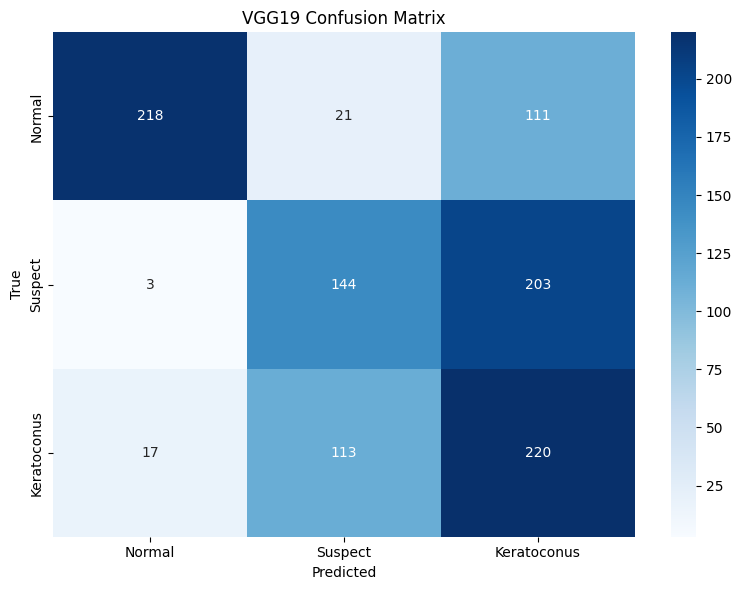

Classification Report:
              precision    recall  f1-score   support

      Normal       0.92      0.62      0.74       350
     Suspect       0.52      0.41      0.46       350
 Keratoconus       0.41      0.63      0.50       350

    accuracy                           0.55      1050
   macro avg       0.62      0.55      0.57      1050
weighted avg       0.62      0.55      0.57      1050



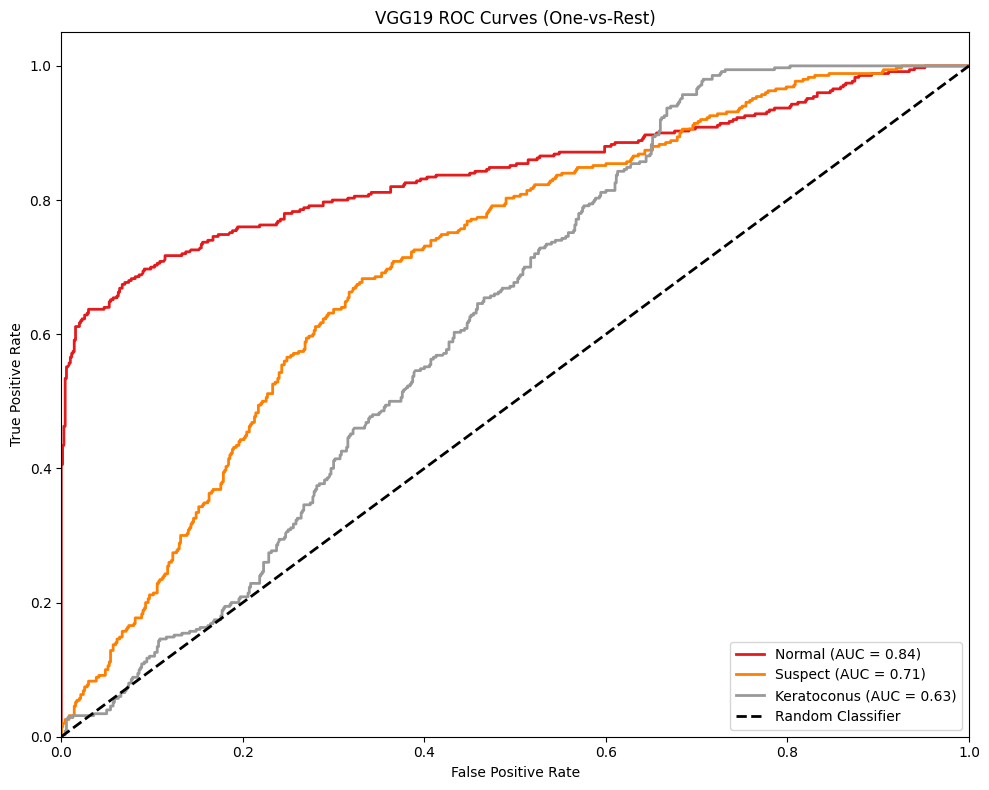

In [ ]:
# Cell 10 — Run training & evaluation for VGG19
print("\n===== TRAINING VGG19 =====")
vgg_model = build_vgg19(num_classes, freeze_base=True)
vgg_model, vgg_history, vgg_best_path = train_model(vgg_model, "VGG19", train_loader, val_loader, epochs=EPOCHS, lr=LEARNING_RATE)
# Load best weights then evaluate on test set
best_epoch = load_checkpoint(vgg_best_path, vgg_model, device=DEVICE)
print("\n===== EVALUATING VGG19 ON TEST SET =====")
vgg_acc, vgg_targets, vgg_preds = evaluate_model(vgg_model, test_loader, class_names=CLASSES, device=DEVICE, model_name="VGG19")


===== TRAINING RESNET50 =====


Epoch 1/20 [Train]:   0%|          | 0/74 [00:00<?, ?it/s]c:\Users\agarw\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\utils\data\dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Epoch 1/20 [Train]: 100%|██████████| 74/74 [02:47<00:00,  2.27s/it, loss=1.01] 


[ResNet50] Epoch 1: Train loss 1.0689, Train acc 0.4827 | Val loss 1.0501, Val acc 0.5363
Saved best model (val_acc: 0.5363) to resnet50_best_model.pth


Epoch 2/20 [Train]: 100%|██████████| 74/74 [02:45<00:00,  2.23s/it, loss=0.981]


[ResNet50] Epoch 2: Train loss 1.0153, Train acc 0.5587 | Val loss 1.0097, Val acc 0.5683
Saved best model (val_acc: 0.5683) to resnet50_best_model.pth


Epoch 3/20 [Train]: 100%|██████████| 74/74 [02:45<00:00,  2.24s/it, loss=0.89] 


... (33 outputs left out)

Epoch 20/20 [Train]: 100%|██████████| 74/74 [02:45<00:00,  2.23s/it, loss=0.656]


[ResNet50] Epoch 20: Train loss 0.7797, Train acc 0.6579 | Val loss 0.8091, Val acc 0.6391
Saved final model to resnet50_final_model.pth

===== EVALUATING RESNET50 ON TEST SET =====


Evaluating ResNet50: 100%|██████████| 33/33 [01:19<00:00,  2.42s/it]


ResNet50 Accuracy: 0.5571



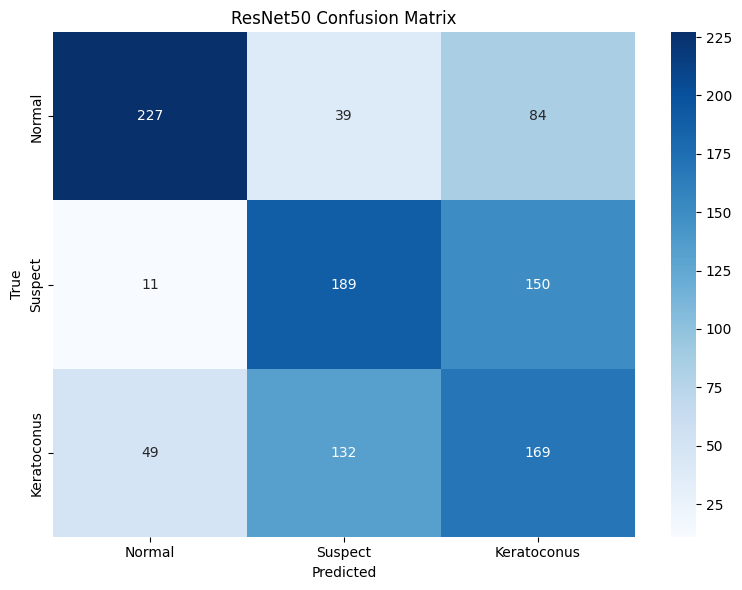

Classification Report:
              precision    recall  f1-score   support

      Normal       0.79      0.65      0.71       350
     Suspect       0.53      0.54      0.53       350
 Keratoconus       0.42      0.48      0.45       350

    accuracy                           0.56      1050
   macro avg       0.58      0.56      0.56      1050
weighted avg       0.58      0.56      0.56      1050



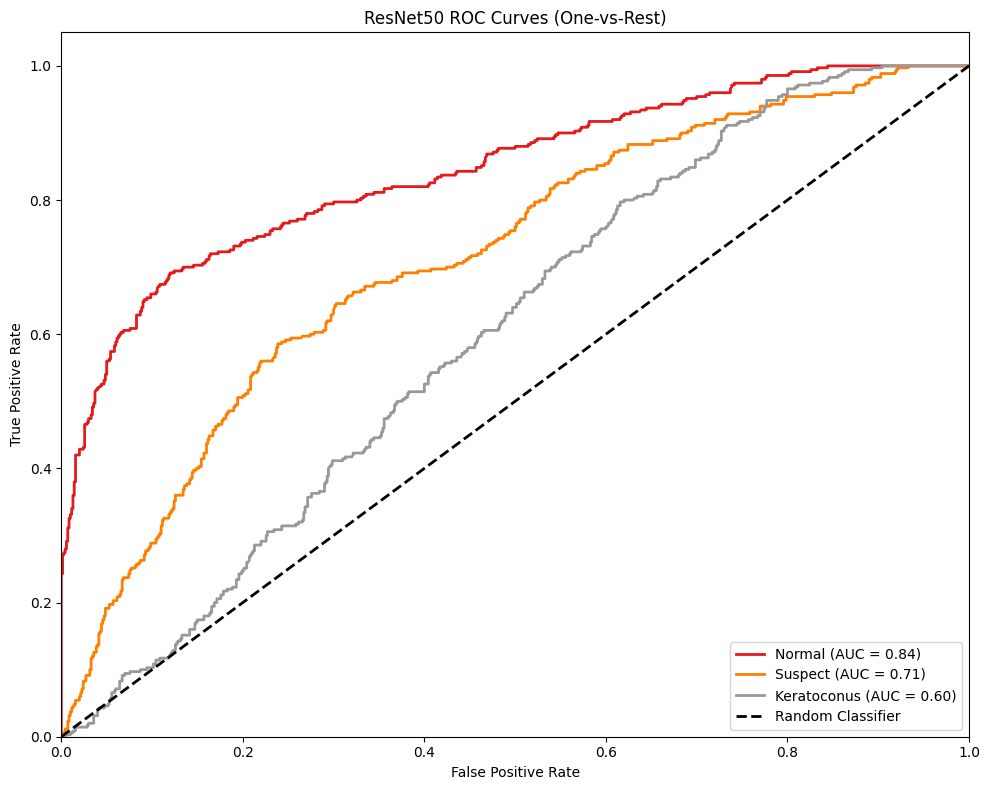

In [ ]:
# Cell 11 — Run training & evaluation for ResNet50
print("\n===== TRAINING RESNET50 =====")
resnet_model = build_resnet50(num_classes, freeze_base=True)
resnet_model, resnet_history, resnet_best_path = train_model(resnet_model, "ResNet50", train_loader, val_loader, epochs=EPOCHS, lr=LEARNING_RATE)
# Load best weights then evaluate on test set
best_epoch = load_checkpoint(resnet_best_path, resnet_model, device=DEVICE)
print("\n===== EVALUATING RESNET50 ON TEST SET =====")
resnet_acc, resnet_targets, resnet_preds = evaluate_model(resnet_model, test_loader, class_names=CLASSES, device=DEVICE, model_name="ResNet50")

In [ ]:
# Cell 12 — Final comparison & save training curves
print("\n--- FINAL COMPARISON ---")
print(f"VGG19 Test Accuracy: {vgg_acc:.4f}")
print(f"ResNet50 Test Accuracy: {resnet_acc:.4f}")
if vgg_acc > resnet_acc:
    print(f"VGG19 performed better by {(vgg_acc - resnet_acc)*100:.2f}%")
else:
    print(f"ResNet50 performed better by {(resnet_acc - vgg_acc)*100:.2f}%")

# Plot histories
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(vgg_history['train_acc'], label='VGG19 Train')
plt.plot(vgg_history['val_acc'], label='VGG19 Val')
plt.plot(resnet_history['train_acc'], label='ResNet Train')
plt.plot(resnet_history['val_acc'], label='ResNet Val')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(vgg_history['train_loss'], label='VGG19 Train')
plt.plot(vgg_history['val_loss'], label='VGG19 Val')
plt.plot(resnet_history['train_loss'], label='ResNet Train')
plt.plot(resnet_history['val_loss'], label='ResNet Val')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.savefig('model_comparison.png')
plt.close()
print("Saved model comparison plot to model_comparison.png")



--- FINAL COMPARISON ---
VGG19 Test Accuracy: 0.5543
ResNet50 Test Accuracy: 0.5571
ResNet50 performed better by 0.29%
Saved model comparison plot to model_comparison.png


In [ ]:
# Cell 13 — Quick inference example on a single image
from PIL import Image
def predict_image(model, image_path, transform=val_test_transform, device=DEVICE, class_names=CLASSES):
    model = model.to(device)
    model.eval()
    img = Image.open(image_path).convert("RGB")
    inp = transform(img).unsqueeze(0).to(device)
    with torch.no_grad():
        out = model(inp)
        probs = torch.nn.functional.softmax(out, dim=1).cpu().numpy()[0]
        pred = np.argmax(probs)
    return class_names[pred], probs

# Example (uncomment and edit image_path)
# image_path = r"C:\path\to\some\image.jpg"
# print(predict_image(vgg_model, image_path))
